# Bight of Biafra, Gold Coast, Bight of Benin: where captives were taken, over time

Three neighbouring stretches of the West African coast supplied about a third of the people
carried across the Atlantic: the Gold Coast (today's Ghana), the Bight of Benin (Togo, Benin
and south-western Nigeria) and the Bight of Biafra (south-eastern Nigeria, Cameroon and the
Gulf of Guinea islands). Different traders worked each coast, so captives from each were taken
to different parts of the Americas. This notebook asks where, quarter-century by
quarter-century, and where Jamaica fits.

Numbers are the voyage database's imputed figures: people disembarked, by the imputed
principal place of embarkation and of disembarkation. They count people on voyages known to
the database, so they are lower bounds for the trade as a whole.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
REGIONS = {
    "Gold Coast": "Gold Coast",
    "Bight of Benin": "Bight of Benin",
    "Bight of Biafra and Gulf of Guinea islands": "Bight of Biafra",
}
three = v.transatlantic.embarked_from(*REGIONS)

In [2]:
three.by("embarkation_region_name")

,embarkation_region_name,voyages,embarked,disembarked
0,Bight of Benin,4636,1534632,1334698
1,Bight of Biafra and Gulf of Guinea islands,3730,1117064,927580
2,Gold Coast,2844,744766,643670


## Destination groups

The database's regions of disembarkation, grouped by the empire that ruled most of them for
most of the trade. Several Caribbean islands changed hands (Grenada, Dominica, St Vincent,
Tobago, St Lucia and Trinidad were French or Spanish for parts of the period), so the groups
are approximate. Jamaica is kept apart from the rest of the British Caribbean.

"Africa" means people landed back in Africa, almost all at Sierra Leone: captives taken off
slaving ships by the Royal Navy after Britain abolished its trade in 1807. "Other or not
known" covers mainland North America, Europe, "Other Caribbean" (the island is not known)
and records that name no region.

In [3]:
GROUPS = {
    "Brazil": ["Amazonia", "Bahia", "Pernambuco", "Southeast Brazil"],
    "Jamaica": ["Jamaica"],
    "Other British Caribbean": [
        "Antigua", "Bahamas", "Barbados", "British Guiana", "Dominica", "Grenada", "Honduras",
        "Montserrat", "Nevis", "Other British Caribbean", "St. Kitts", "St. Lucia",
        "St. Vincent", "Tobago", "Tortola", "Trinidad",
    ],
    "French Caribbean": [
        "Saint-Domingue", "Martinique", "Guadaloupe", "French Guiana", "Other French Caribbean",
    ],
    "Spanish Americas": [
        "Cuba", "Puerto Rico", "Hispaniola", "Other Spanish Caribbean",
        "Spanish Circum-Caribbean", "Rio de la Plata", "Spanish Americas",
    ],
    "Dutch, Danish, Swedish": [
        "Dutch Caribbean", "Dutch Guianas", "Danish West Indies", "St. Barthélemy (Sweden)",
    ],
}  # fmt: skip
ORDER = [*GROUPS, "Africa", "Other or not known"]
GROUP_OF = {region: group for group, regions in GROUPS.items() for region in regions}

rows = three.to_pandas(
    [
        "voyage_id",
        "embarkation_region_name",
        "disembarkation_region_name",
        "disembarkation_broad_region_name",
        "year_arrived_imputed",
        "disembarked_imputed",
    ]
)
rows["region"] = rows.embarkation_region_name.map(REGIONS)
rows["destination"] = pd.Categorical(
    [
        GROUP_OF.get(r, "Africa" if b == "Africa" else "Other or not known")
        for r, b in zip(
            rows.disembarkation_region_name, rows.disembarkation_broad_region_name, strict=True
        )
    ],
    ORDER,
)
rows["period"] = (rows.year_arrived_imputed - 1) // 25 * 25 + 1  # 1701 = 1701-1725

What falls into "Other or not known", by broad region. The only Caribbean entry should be
"Other Caribbean"; nothing from Brazil or Spanish America should be here.

In [4]:
other = (
    rows[rows.destination == "Other or not known"]
    .groupby("disembarkation_broad_region_name", dropna=False)
    .disembarked_imputed.sum()
    .astype(int)
)
other

disembarkation_broad_region_name
Caribbean                   6289
Europe                      1504
Mainland North America     73878
Other                      31596
NaN                       103837
Name: disembarked_imputed, dtype: int64

## Over the whole trade

Share of people disembarked, by destination group, for each African region.

In [5]:
people = rows.pivot_table(
    index="destination", columns="region", values="disembarked_imputed",
    aggfunc="sum", observed=False,
)[list(REGIONS.values())].fillna(0).astype(int)  # fmt: skip
shares = (people / people.sum() * 100).round(1)
shares

region,Gold Coast,Bight of Benin,Bight of Biafra
destination,,,
Brazil,6.2,54.8,10.6
Jamaica,31.1,6.2,24.9
Other British Caribbean,25.1,6.0,30.5
French Caribbean,6.9,16.5,7.4
Spanish Americas,2.7,4.2,11.0
"Dutch, Danish, Swedish",14.9,5.8,2.6
Africa,0.2,3.0,3.6
Other or not known,12.8,3.6,9.4


The three coasts fed different empires:

- **Bight of Benin**: Brazil above all, and within Brazil, Bahia. Saint-Domingue and the other
  French islands come second.
- **Bight of Biafra** and **Gold Coast**: the British Caribbean, with Jamaica the largest
  single destination for both.
- The Gold Coast also supplied the Dutch and Danish colonies, whose trading forts stood on
  that coast (Elmina, Christiansborg).

In [6]:
landing_regions = (
    rows.groupby(["region", "disembarkation_region_name"])
    .disembarked_imputed.sum()
    .groupby(level=0, group_keys=False)
    .nlargest(3)
    .astype(int)
    .rename("people")
    .reset_index()
)
landing_regions["share"] = (
    landing_regions.people
    / landing_regions.region.map(rows.groupby("region").disembarked_imputed.sum())
    * 100
).round(1)
landing_regions

,region,disembarkation_region_name,people,share
0,Bight of Benin,Bahia,651333,48.8
1,Bight of Benin,Saint-Domingue,160034,12.0
2,Bight of Benin,Jamaica,82287,6.2
3,Bight of Biafra,Jamaica,230965,24.9
4,Bight of Biafra,Cuba,67992,7.3
5,Bight of Biafra,Barbados,63272,6.8
6,Gold Coast,Jamaica,200135,31.1
7,Gold Coast,Barbados,59416,9.2
8,Gold Coast,Dutch Guianas,51733,8.0


## Over time

People disembarked by quarter-century of arrival, for each African region. The panels share
one scale.

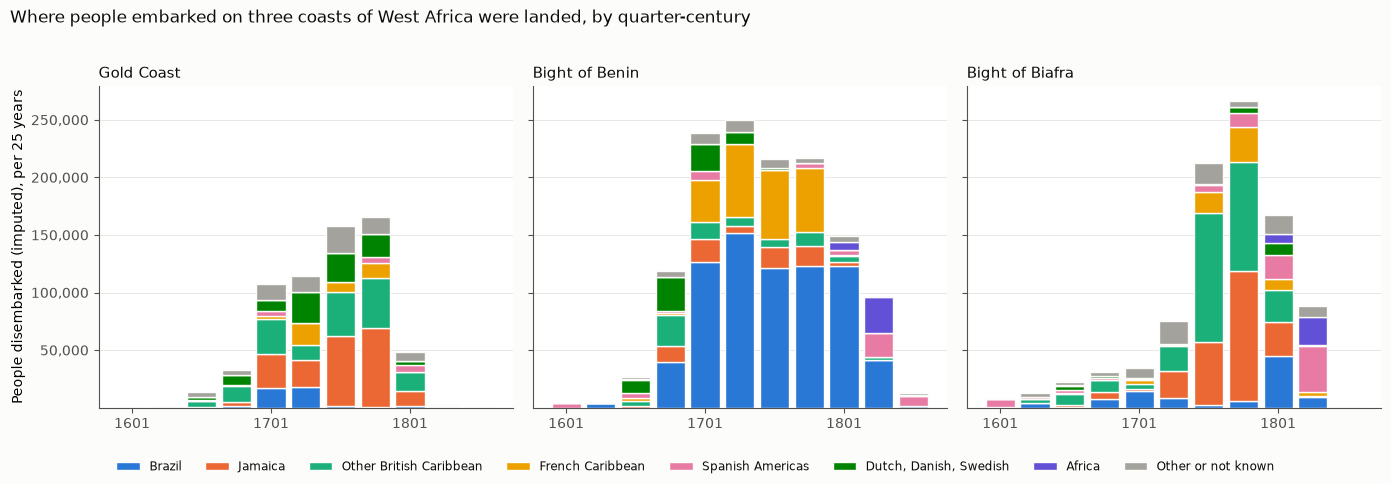

In [7]:
by_period = rows.pivot_table(
    index="period", columns=["region", "destination"], values="disembarked_imputed",
    aggfunc="sum", observed=False,
).fillna(0).astype(int)  # fmt: skip
by_period = by_period.loc[1601:1851]

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3dd"
# Categorical slots 1-7 in fixed order; the last group is folded into a neutral.
COLOURS = dict(
    zip(
        ORDER,
        ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#a3a29c"],
        strict=True,
    )
)
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, region in zip(axes, REGIONS.values(), strict=True):
    data = by_period[region]
    bottom = pd.Series(0, index=data.index)
    for group in ORDER:
        ax.bar(
            data.index, data[group], width=21, bottom=bottom, color=COLOURS[group],
            edgecolor=SURFACE, linewidth=1, label=group,
        )  # fmt: skip
        bottom += data[group]
    ax.set_title(region, loc="left", fontsize=11)
    ax.set_xticks([1601, 1701, 1801], ["1601", "1701", "1801"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel("People disembarked (imputed), per 25 years")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=8, frameon=False, fontsize=8.5)
fig.suptitle(
    "Where people embarked on three coasts of West Africa were landed, by quarter-century",
    x=0.01, ha="left", fontsize=12,
)  # fmt: skip
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
fig.savefig("figures/04_destinations_by_period.png", dpi=150)

The same, as shares of each quarter-century's people. Quarter-centuries with fewer than
10,000 people disembarked are left out, because their shares rest on a handful of voyages.

In [8]:
totals = by_period.T.groupby(level="region").sum().T
period_shares = {
    region: (by_period[region].div(totals[region], axis=0) * 100)
    .loc[totals[region] >= 10_000]
    .round(0)
    .astype(int)
    for region in REGIONS.values()
}
period_shares["Gold Coast"]

destination,Brazil,Jamaica,Other British Caribbean,French Caribbean,Spanish Americas,"Dutch, Danish, Swedish",Africa,Other or not known
period,,,,,,,,
1651,0,3,41,2,2,22,3,27
1676,4,11,43,2,0,27,0,12
1701,16,28,28,2,4,9,0,12
1726,15,20,12,16,0,23,0,12
1751,1,39,24,6,0,16,0,15
1776,0,41,26,8,3,12,0,9
1801,4,26,34,1,12,7,1,16


In [9]:
period_shares["Bight of Benin"]

destination,Brazil,Jamaica,Other British Caribbean,French Caribbean,Spanish Americas,"Dutch, Danish, Swedish",Africa,Other or not known
period,,,,,,,,
1651,0,6,16,11,17,41,2,7
1676,33,12,22,2,1,25,0,4
1701,53,9,6,15,3,10,0,4
1726,61,3,3,25,0,4,0,4
1751,56,9,3,27,0,1,0,4
1776,57,8,6,26,2,0,0,2
1801,83,2,4,0,3,1,4,3
1826,42,0,3,0,21,0,32,2
1851,10,0,0,0,70,0,11,9


In [10]:
period_shares["Bight of Biafra"]

destination,Brazil,Jamaica,Other British Caribbean,French Caribbean,Spanish Americas,"Dutch, Danish, Swedish",Africa,Other or not known
period,,,,,,,,
1626,35,0,24,0,12,0,1,28
1651,1,12,41,5,11,16,4,12
1676,24,20,33,1,4,8,0,10
1701,42,4,13,11,2,3,0,25
1726,11,31,29,2,0,0,0,27
1751,1,26,53,9,3,0,0,8
1776,2,42,35,12,5,2,0,2
1801,27,18,17,5,13,6,5,10
1826,11,0,1,3,45,1,27,10


What changes:

- **Bight of Benin.** Brazil's share is over half in every quarter-century from 1701 to 1825,
  and peaks at 83% in 1801–1825, after British ships had left the trade. The French islands
  took about a quarter in 1726–1800, until the Haitian Revolution ended slavery in
  Saint-Domingue.
- **Bight of Biafra.** The British Caribbean takes most people from 1751 to 1800. Jamaica's
  share is highest in 1776–1800. After British abolition in 1807 the coast's captives go to
  Cuba and Brazil, and many are taken off ships and landed at Sierra Leone.
- **Gold Coast.** Jamaica takes about two-fifths of the coast's people in 1751–1800.
  The Gold Coast trade almost ends after 1807, because British ships had carried most of it.

## Jamaica's share

Share of each region's people, per quarter-century, who were landed in Jamaica, from 1651 to
1825. Britain ended its slave trade in 1807, and almost no one was landed in Jamaica from
Africa after that.

In [11]:
jamaica_share = pd.DataFrame(
    {region: period_shares[region]["Jamaica"] for region in REGIONS.values()}
).loc[1651:1801]
jamaica_share

,Gold Coast,Bight of Benin,Bight of Biafra
period,,,
1651,3.0,6.0,12.0
1676,11.0,12.0,20.0
1701,28.0,9.0,4.0
1726,20.0,3.0,31.0
1751,39.0,9.0,26.0
1776,41.0,8.0,42.0
1801,26.0,2.0,18.0


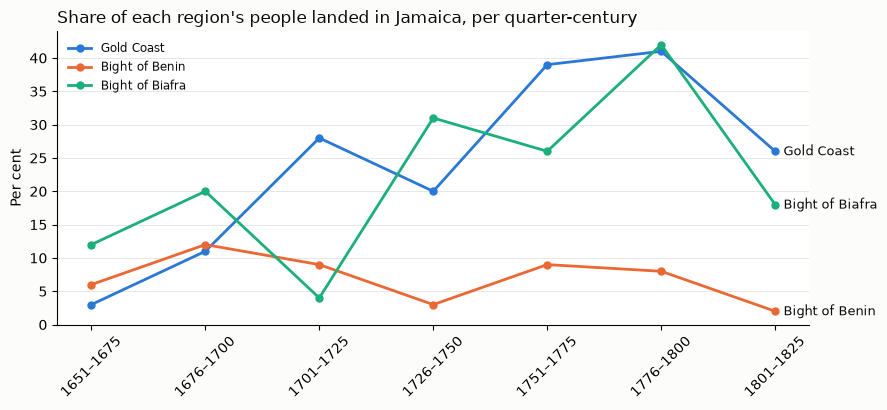

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
LINE = {"Gold Coast": "#2a78d6", "Bight of Benin": "#eb6834", "Bight of Biafra": "#1baf7a"}
for region, colour in LINE.items():
    s = jamaica_share[region].dropna()
    ax.plot(s.index, s.values, color=colour, linewidth=2, marker="o", markersize=5, label=region)
    ax.annotate(
        region, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points",
        va="center", fontsize=9, color=INK,
    )  # fmt: skip
ax.set_title("Share of each region's people landed in Jamaica, per quarter-century", loc="left")
ax.set_ylabel("Per cent")
ax.set_xticks(jamaica_share.index, [f"{p}–{p + 24}" for p in jamaica_share.index], rotation=45)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.tight_layout()
fig.savefig("figures/04_jamaica_share.png", dpi=150)

## Checks

The figures quoted above, checked against the tables.

In [13]:
allowed = {"Mainland North America", "Europe", "Other", "Caribbean"}
assert set(other.index.dropna()) <= allowed, other
unknown_islands = rows[
    (rows.destination == "Other or not known")
    & (rows.disembarkation_broad_region_name == "Caribbean")
]
assert set(unknown_islands.disembarkation_region_name) == {"Other Caribbean"}
assert shares.loc["Brazil", "Bight of Benin"] == 54.8
assert (
    landing_regions.query("region == 'Bight of Benin'").iloc[0].disembarkation_region_name
    == "Bahia"
)
british = shares.loc[["Jamaica", "Other British Caribbean"]].sum()
assert (round(british["Bight of Biafra"], 1), round(british["Gold Coast"], 1)) == (55.4, 56.2)
for region in ("Bight of Biafra", "Gold Coast"):
    top = landing_regions.query("region == @region").iloc[0]
    assert top.disembarkation_region_name == "Jamaica", region
benin = period_shares["Bight of Benin"]
assert (benin.loc[1701:1801, "Brazil"] > 50).all() and benin.loc[1801, "Brazil"] == 83
assert benin.loc[1726:1776, "French Caribbean"].between(25, 27).all()
assert jamaica_share["Bight of Biafra"].idxmax() == 1776
assert jamaica_share.loc[[1751, 1776], "Gold Coast"].tolist() == [39, 41]
assert period_shares["Bight of Biafra"].loc[1826, ["Spanish Americas", "Africa"]].tolist() == [
    45,
    27,
]
assert totals.loc[1826, "Gold Coast"] < 10_000

In [14]:
voyages.citation()

'SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).'